In [1]:
from IPython.display import Image

## Рекомендательные системы

Рекомендательная система — это набор алгоритмов, программ и сервисов, которые помогают определить, какие объекты, товары или материалы могут быть интересны конкретному пользователю. Ее основная задача — предсказать предпочтения человека и предложить ему наиболее подходящие варианты из тех, с которыми он, возможно, еще не знаком.

Такие системы анализируют информацию о пользователе: его прошлые действия, оценки, просмотры, покупки, поисковые запросы, а иногда и данные о похожих пользователях. На основе этого формируются персонализированные рекомендации. Иными словами, рекомендательная система старается понять интересы человека и заранее предложить то, что с высокой вероятностью ему подойдет.

Наиболее часто рекомендательные системы используются в сервисах, где человеку нужно выбирать из большого количества вариантов. Например, в интернет-магазинах они предлагают товары, которые могут заинтересовать покупателя; в онлайн-кинотеатрах — фильмы и сериалы; в музыкальных сервисах — исполнителей, альбомы и плейлисты; в социальных сетях — публикации, группы, друзей или видео. Также такие системы применяются в новостных платформах, образовательных сервисах, маркетплейсах, мобильных приложениях и даже в медицине, где можно рекомендовать подходящие программы наблюдения или обучения.

Рекомендации упрощают процесс выбора и помогают пользователю быстрее находить полезный и интересный контент. Например, при регистрации в Netflix пользователю предлагают отметить понравившиеся фильмы или сериалы. На основе этого сервис формирует стартовую подборку. В дальнейшем система уточняет рекомендации с учетом того, что человек смотрит, какие оценки ставит и что добавляет в избранное. Похожим образом работает YouTube, предлагая видео на основе истории просмотров, а Ozon или Wildberries — товары, связанные с предыдущими покупками и интересами пользователя. В Spotify рекомендательная система может предлагать новые треки и исполнителей, похожих на те, которые пользователь слушает чаще всего.

«Объект» (item, object) — элемент, который система может рекомендовать пользователю. Это может быть товар, фильм, музыкальная композиция, книга, новость, видео, курс и т.д. Для объекта определяется степень сходства с другими объектами или степень его привлекательности для конкретного пользователя.

«Пользователь» (user) — человек или иной субъект, для которого формируются рекомендации.
Для пользователя характерно следующее:

именно для него система пытается подобрать рекомендации;

его действия, оценки и предпочтения могут сохраняться в системе;

на основе его поведения можно строить персонализированные предложения;

в системе могут использоваться данные как о самом пользователе, так и о других пользователях с похожими интересами.

Иногда выделяют:

текущего пользователя — того, для кого в данный момент строится рекомендация;

похожих пользователей — пользователей со схожими интересами, оценками или поведением.

Далее можно ввести еще несколько важных терминов:

«Предпочтение» (preference) — степень интереса пользователя к объекту.
Предпочтение может быть выражено явно, например через оценку, лайк или дизлайк, либо неявно — через просмотр, покупку, добавление в избранное, длительность просмотра и другие действия.

«Рейтинг» (rating) — численная или категориальная оценка объекта пользователем.
Например, оценка фильма по шкале от 1 до 5 звезд. Рейтинг часто используется для обучения рекомендательной системы.

«Профиль пользователя» (user profile) — совокупность сведений о пользователе, которые помогают формировать рекомендации.
Профиль может включать историю просмотров, покупок, поисковых запросов, оценок, выбранных категорий и другую информацию.

«Матрица пользователь – объект» (user–item matrix) — таблица, в которой отражено взаимодействие пользователей с объектами.
Обычно строки соответствуют пользователям, столбцы — объектам, а в ячейках находятся оценки, просмотры, покупки или иные признаки взаимодействия.

«Рекомендация» (recommendation) — результат работы системы, то есть список объектов, которые с наибольшей вероятностью будут интересны пользователю.

### Матрица предпочтений (рейтингов)

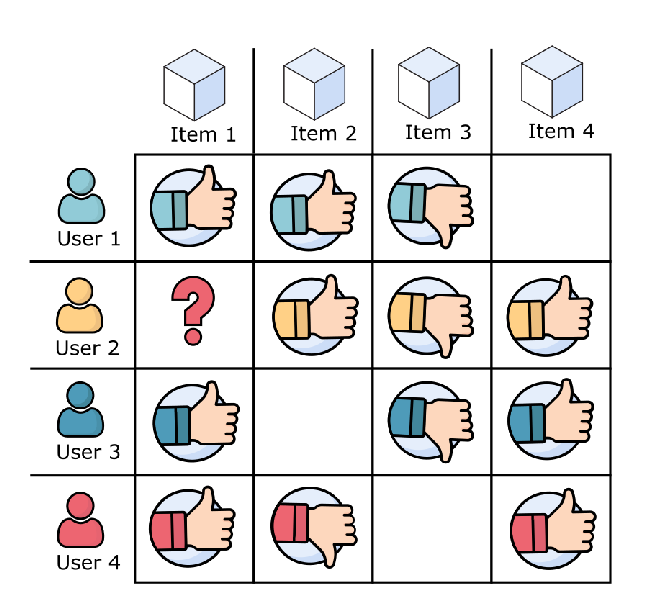

In [2]:
Image('matrix.png', width='50%')

In [2]:
import pandas as pd

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
import warnings

warnings.filterwarnings('ignore')

## Знакомство с данными

Задача: рекомендовать фильмы на основе оценок пользователей

In [5]:
movies_data = pd.read_csv('movies.csv')
ratings_data = pd.read_csv('ratings.csv')

In [6]:
movies_data.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [7]:
ratings_data.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [8]:
ratings_data['rating'].unique()

array([4. , 5. , 3. , 2. , 1. , 4.5, 3.5, 2.5, 0.5, 1.5])

<Axes: >

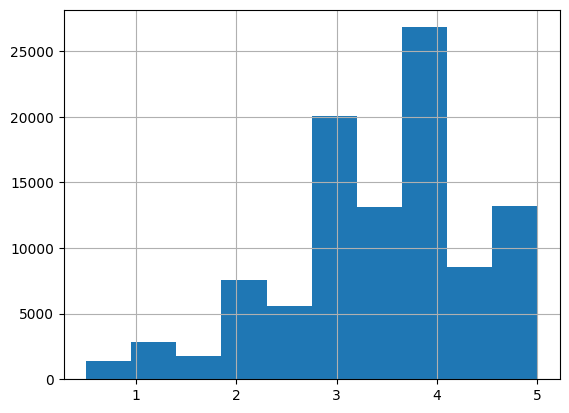

In [9]:
ratings_data['rating'].hist()

In [10]:
ratings_data.describe()

,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


In [11]:
data = pd.merge(movies_data, ratings_data, on='movieId').drop('genres', axis=1)
data.head()

,movieId,title,userId,rating,timestamp
0,1,Toy Story (1995),1,4.0,964982703
1,1,Toy Story (1995),5,4.0,847434962
2,1,Toy Story (1995),7,4.5,1106635946
3,1,Toy Story (1995),15,2.5,1510577970
4,1,Toy Story (1995),17,4.5,1305696483


In [12]:
# Вычисление среднего рейтинга фильмов
ratings = pd.DataFrame(data.groupby('title')['rating'].mean())
ratings.head()

,rating
title,
'71 (2014),4.0
'Hellboy': The Seeds of Creation (2004),4.0
'Round Midnight (1986),3.5
'Salem's Lot (2004),5.0
'Til There Was You (1997),4.0


In [13]:
ratings['number_of_ratings'] = data.groupby('title')['rating'].count()
ratings.head()

,rating,number_of_ratings
title,,
'71 (2014),4.0,1
'Hellboy': The Seeds of Creation (2004),4.0,1
'Round Midnight (1986),3.5,2
'Salem's Lot (2004),5.0,1
'Til There Was You (1997),4.0,2


In [14]:
# Отберем фильмы с достаточным количеством оценок
ratings = ratings.sort_values(by='number_of_ratings', ascending=False)
ratings[ratings['number_of_ratings'] > 25].sample(10)

,rating,number_of_ratings
title,,
"Piano, The (1993)",3.540984,61
Primal Fear (1996),3.642857,35
"Untouchables, The (1987)",3.938462,65
Spy Game (2001),3.481481,27
Forever Young (1992),2.851852,27
Billy Madison (1995),3.326531,49
Wallace & Gromit: The Wrong Trousers (1993),4.035714,56
Pride & Prejudice (2005),3.555556,27
Dark City (1998),3.822917,48


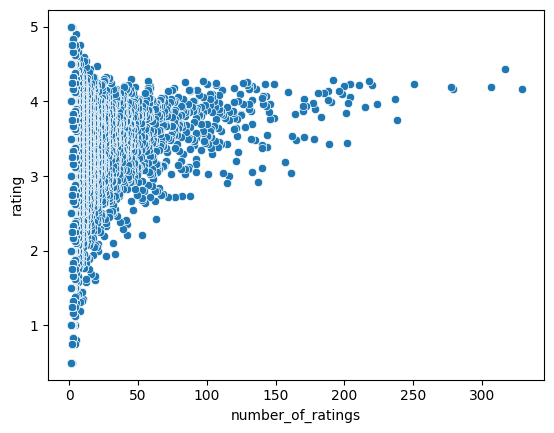

In [15]:
sns.scatterplot(ratings, x='number_of_ratings', y='rating')
plt.show()

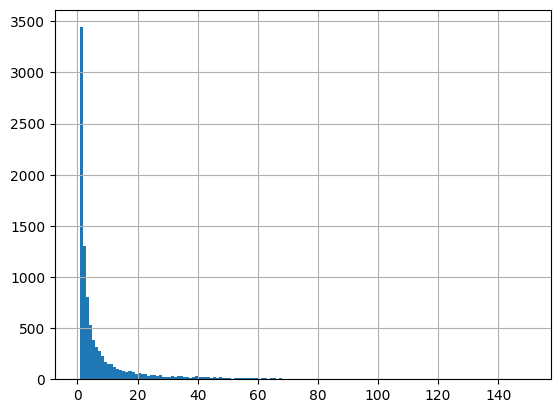

In [16]:
ratings['number_of_ratings'].hist(bins=150, range=(0,150))
plt.show()

### Классификация рекомендательных систем

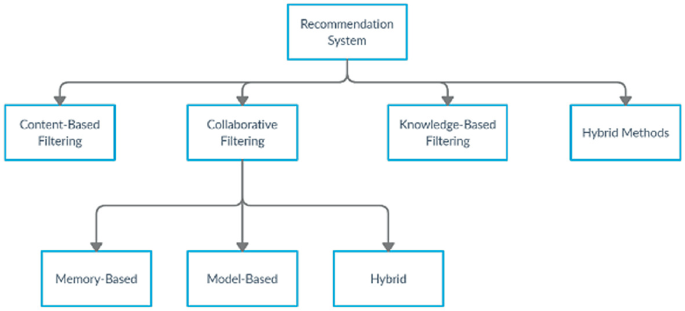

In [17]:
Image('classification_rec.png', width='75%')

## Коллаборативная фильтрация

Коллаборативная фильтрация — это один из наиболее распространённых подходов в рекомендательных системах. Его основная идея заключается в том, что рекомендации для пользователя формируются на основе поведения других пользователей.

Методы коллаборативной фильтрации строят рекомендации, анализируя сходство между пользователями или объектами. Предполагается, что если два пользователя имеют похожие интересы и ставят похожие оценки объектам, то и в будущем им могут понравиться одинаковые элементы.

Таким образом, система может предложить пользователю новый объект, опираясь на оценки других пользователей со схожими предпочтениями.

Методы коллаборативной фильтрации используют историю взаимодействия пользователей с объектами.

Основная идея метода состоит в том, что пользователю можно рекомендовать те объекты, которые понравились людям с похожими интересами, либо те объекты, которые похожи на те, что он уже высоко оценил.

Методы коллаборативной фильтрации принято подразделять на два основных типа:

1. Эвристические методы (memory-based)
Данные методы используют непосредственно матрицу пользователь–объект и вычисляют сходство между пользователями или объектами.
Рекомендации формируются на основе ближайших «соседей».

Наиболее распространённые варианты:

user-based — поиск пользователей с похожими интересами;

item-based — поиск объектов, похожих на те, которые пользователь уже оценил.

2. Модели предпочтений (model-based)
В этом подходе сначала строится математическая модель, которая описывает поведение пользователей и их предпочтения. После обучения модель используется для прогнозирования того, насколько объект может понравиться пользователю.

## Memory-based

Данный подход подразделяется на `User-based` коллаборативную фильтрацию и `Item-based` коллаборативную фильтрацию.

1. User-based filtering

Принцип работы следующий:

Система анализирует оценки пользователей.

Определяет пользователей, которые оценивают объекты похожим образом.

Находит пользователей с наиболее похожими интересами.

Рекомендует текущему пользователю объекты, которые понравились этим пользователям.

2. Item-based filtering

Принцип работы:

Анализируется, какие объекты пользователи оценивают похожим образом.

Вычисляется сходство между объектами.

Если пользователь высоко оценил один объект, система рекомендует похожие объекты.

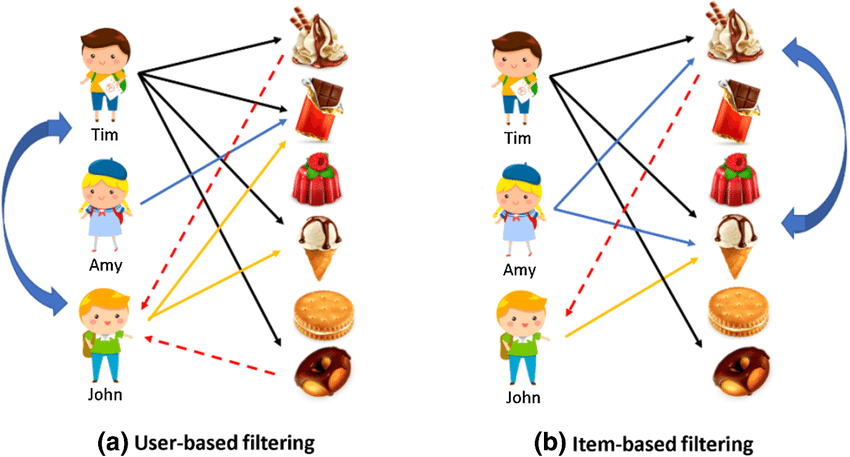

In [18]:
Image('User-based-and-item-based-filtering.png', width='75%')

### Метод item-based:

1. Для текущего пользователя определяется текущий объект (объект, который наиболее предпочтителен для формирования рекомендаций).
2. Определяются объекты, наиболее похожие по оценкам на текущий объект, из них может быть выбрано K наиболее похожих.

При вычислении прогноза $r_{ui}$ оценивается схожесть объектов пользователя с объектом $i$ и считается взвешенная сумма:
$$
    r_{ui} = \overline{r_i} + \frac
    {\sum_{j \in Item_u}\big(\textit{sim(i, j)} \times (r_{uj} - \overline{r_j})\big)}
    {\sum_{j \in Item_u}\textit{sim(i, j)}}
$$

Для оценки схожести двух объектов также используется корреляция Пирсона:
$$
    \textit{sim(i, j)} = \frac
    {\sum_u{\big((r_{ui} - \overline{r_i}) \times (r_{uj} - \overline{r_j})\big)}}
    {\sqrt{\sum_u{(r_{ui} - \overline{r_i})^2}} \times \sqrt{\sum_u{(r_{uj} - \overline{r_j})^2}}}
$$

### Метод user-based:

1. Определяются пользователи, наиболее похожие по оценкам на текущего пользователя (для которого формируется рекомендация).
2. Для найденных пользователей находятся наиболее позитивно оцененные объекты, которые еще неизвестны текущему пользователю (текущий пользователь еще не оценивал эти объекты).
3. Найденные объекты предлагаются текущему пользователю.

Определять схожесть $2$ пользователей можно с помощью `корреляции Пирсона` между векторами уже поставленными оценками. 

Особенности данного показателя:
1. Два различных пользователя могут иметь мало общих фильмов, но при этом корреляция показывает большую схожесть, а иногда и вовсе $1$. Чтобы избежать этого, в числителе нужно считать только общий рейтинг, а знаменатель по всем рейтингам;
2. Для двух различных пользователей оценка может иметь различный вес. Например, для одного средний фильм имеет рейтинг $2$, а для другого $4$. Такие пользователи похожи, но корреляция скажет, что они различны. Чтобы устранить это, из всех оценок пользователя вычитается его средняя оценка.

**Формула схожести двух пользователей**:
$$
    \textit{sim(u, v)} = \frac
    {\sum_i{\big((r_{ui} - \overline{r_u}) \times (r_{vi} - \overline{r_v})\big)}}
    {\sqrt{\sum_i{(r_{ui} - \overline{r_u})^2}} \times \sqrt{\sum_i{(r_{vi} - \overline{r_v})^2}}}
$$

**Рейтинг для пользователя** можно оценить как средний рейтинг между схожими пользователями, но, благодаря введению понятия схожести, можно улучшить эту оценку, введя взвешенные веса и учитывая всех пользователей, которые посмотрели этот объект:
$$
    r_{ui} = \overline{r_v} + \frac
    {\sum_{v \in User_i}\big(\textit{sim(u, v)} \times (r_{vi} - \overline{r_v})\big)}
    {\sum_{v \in User_i}\textit{sim(u, v)}}
$$

In [19]:
# Cоздаем матрицу предпочтений (рейтингов)
movie_matrix = data.pivot_table(index='userId', columns='title', values='rating')
movie_matrix.head()

title,'71 (2014),'Hellboy': The Seeds of Creation (2004),'Round Midnight (1986),'Salem's Lot (2004),'Til There Was You (1997),'Tis the Season for Love (2015),"'burbs, The (1989)",'night Mother (1986),(500) Days of Summer (2009),*batteries not included (1987),...,Zulu (2013),[REC] (2007),[REC]² (2009),[REC]³ 3 Génesis (2012),anohana: The Flower We Saw That Day - The Movie (2013),eXistenZ (1999),xXx (2002),xXx: State of the Union (2005),¡Three Amigos! (1986),À nous la liberté (Freedom for Us) (1931)
userId,,,,,,,,,,,,,,,,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
movie_matrix.shape

(610, 9719)

In [21]:
movie_matrix.fillna(0, inplace = True)
movie_matrix.head()

title,'71 (2014),'Hellboy': The Seeds of Creation (2004),'Round Midnight (1986),'Salem's Lot (2004),'Til There Was You (1997),'Tis the Season for Love (2015),"'burbs, The (1989)",'night Mother (1986),(500) Days of Summer (2009),*batteries not included (1987),...,Zulu (2013),[REC] (2007),[REC]² (2009),[REC]³ 3 Génesis (2012),anohana: The Flower We Saw That Day - The Movie (2013),eXistenZ (1999),xXx (2002),xXx: State of the Union (2005),¡Three Amigos! (1986),À nous la liberté (Freedom for Us) (1931)
userId,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Нужно учитывать количество отзывов, т.к. может порекомендоваться фильм с одним положительным отзывом. Лучше всего отсеивать по примерно тому же количеству отзывов

In [22]:
movie_mask = ratings[ratings['number_of_ratings'] > 20].index

In [23]:
movie_matrix = movie_matrix.loc[:, movie_mask]

In [24]:
movie_matrix

title,Forrest Gump (1994),"Shawshank Redemption, The (1994)",Pulp Fiction (1994),"Silence of the Lambs, The (1991)","Matrix, The (1999)",Star Wars: Episode IV - A New Hope (1977),Jurassic Park (1993),Braveheart (1995),Terminator 2: Judgment Day (1991),Schindler's List (1993),...,"Walk in the Clouds, A (1995)",Mulholland Falls (1996),"Ghost and the Darkness, The (1996)","Money Pit, The (1986)",Shrek the Third (2007),"Help, The (2011)","Little Princess, A (1995)",Bridesmaids (2011),"Secret of NIMH, The (1982)",13 Going on 30 (2004)
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,3.0,4.0,5.0,5.0,4.0,4.0,0.0,5.0,...,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0
2,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,5.0,1.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,3.0,5.0,0.0,0.0,0.0,0.0,4.0,3.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,4.0,3.5,5.0,4.5,5.0,4.5,2.5,3.5,3.5,5.0,...,3.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
607,0.0,5.0,3.0,5.0,5.0,3.0,4.0,5.0,4.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
608,3.0,4.5,5.0,4.0,5.0,3.5,3.0,4.0,3.0,4.0,...,0.0,0.0,3.5,2.5,0.0,0.0,0.0,0.0,0.0,0.0


## Метод ближайших соседей

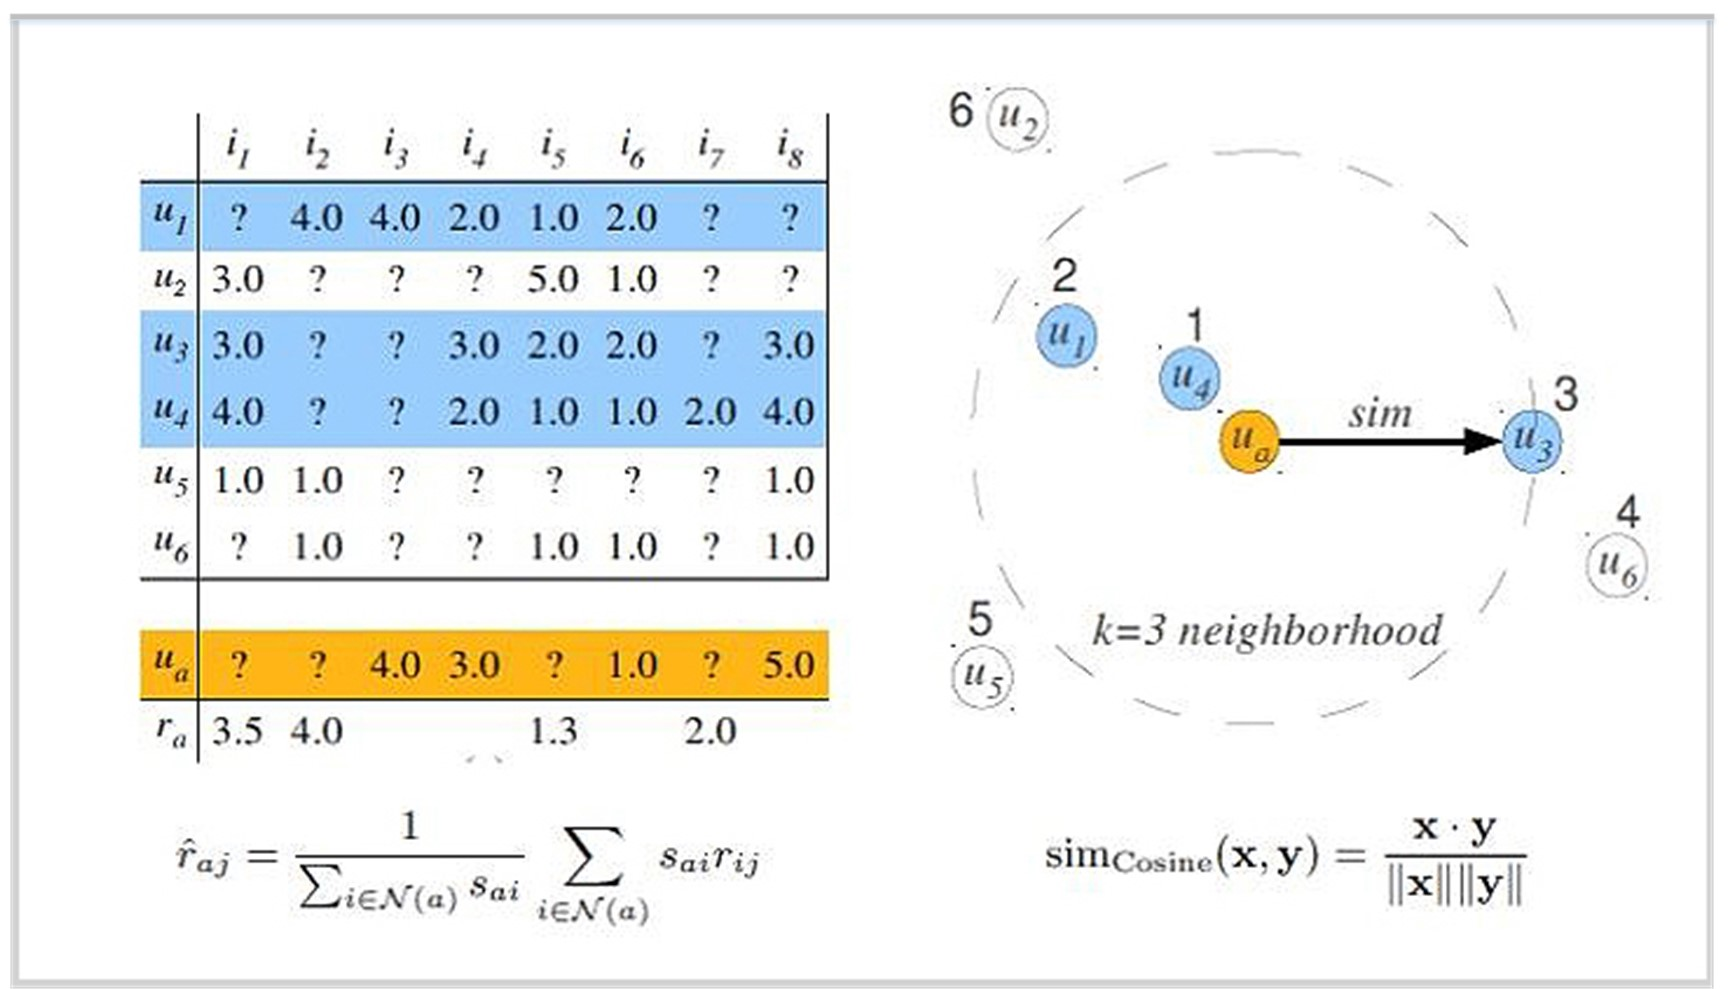

In [25]:
Image('knn.jpeg', width='100%')

In [26]:
# для работы с разреженными матрицами
from scipy.sparse import csr_matrix

csr_data = csr_matrix(movie_matrix.values.T)

In [27]:
csr_data

<1235x610 sparse matrix of type '<class 'numpy.float64'>'
	with 66658 stored elements in Compressed Sparse Row format>

In [28]:
movie_matrix

title,Forrest Gump (1994),"Shawshank Redemption, The (1994)",Pulp Fiction (1994),"Silence of the Lambs, The (1991)","Matrix, The (1999)",Star Wars: Episode IV - A New Hope (1977),Jurassic Park (1993),Braveheart (1995),Terminator 2: Judgment Day (1991),Schindler's List (1993),...,"Walk in the Clouds, A (1995)",Mulholland Falls (1996),"Ghost and the Darkness, The (1996)","Money Pit, The (1986)",Shrek the Third (2007),"Help, The (2011)","Little Princess, A (1995)",Bridesmaids (2011),"Secret of NIMH, The (1982)",13 Going on 30 (2004)
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,3.0,4.0,5.0,5.0,4.0,4.0,0.0,5.0,...,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0
2,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,5.0,1.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,3.0,5.0,0.0,0.0,0.0,0.0,4.0,3.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606,4.0,3.5,5.0,4.5,5.0,4.5,2.5,3.5,3.5,5.0,...,3.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
607,0.0,5.0,3.0,5.0,5.0,3.0,4.0,5.0,4.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
608,3.0,4.5,5.0,4.0,5.0,3.5,3.0,4.0,3.0,4.0,...,0.0,0.0,3.5,2.5,0.0,0.0,0.0,0.0,0.0,0.0


In [29]:
from sklearn.neighbors import NearestNeighbors

# создадим объект класса NearestNeighbors
knn = NearestNeighbors(metric = 'cosine', algorithm = 'brute', n_neighbors = 20, n_jobs = -1)
 
# обучим модель
knn.fit(csr_data)

NearestNeighbors(algorithm='brute', metric='cosine', n_jobs=-1, n_neighbors=20)

Такой формат часто используется при item-based рекомендациях, где необходимо анализировать сходство между фильмами.

In [30]:
movie_matrix_copy = movie_matrix.copy(deep=True)

In [31]:
movie_matrix_copy = movie_matrix_copy.T

Удаляет имя оси столбцов. Это делается для того, чтобы таблица имела более удобный и чистый формат.

Переносит индекс таблицы (названия фильмов) в отдельный столбец.

Теперь названия фильмов становятся обычным столбцом title, а индекс заменяется на стандартную нумерацию.

In [32]:
movie_matrix_copy = movie_matrix_copy.rename_axis(None, axis = 1).reset_index()
movie_matrix_copy.head()

,title,1,2,3,4,5,6,7,8,9,...,601,602,603,604,605,606,607,608,609,610
0,Forrest Gump (1994),4.0,0.0,0.0,0.0,0.0,5.0,5.0,3.0,0.0,...,0.0,3.0,3.0,0.0,3.0,4.0,0.0,3.0,4.0,3.0
1,"Shawshank Redemption, The (1994)",0.0,3.0,0.0,0.0,3.0,5.0,0.0,5.0,0.0,...,5.0,5.0,0.0,0.0,0.0,3.5,5.0,4.5,4.0,3.0
2,Pulp Fiction (1994),3.0,0.0,0.0,1.0,5.0,2.0,0.0,4.0,0.0,...,0.0,5.0,5.0,5.0,2.0,5.0,3.0,5.0,4.0,5.0
3,"Silence of the Lambs, The (1991)",4.0,0.0,0.0,5.0,0.0,4.0,5.0,4.0,0.0,...,0.0,5.0,5.0,5.0,0.0,4.5,5.0,4.0,0.0,4.5
4,"Matrix, The (1999)",5.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,5.0,0.0,5.0,0.0,0.0,5.0,5.0,5.0,0.0,5.0


In [33]:
movie = 'Fight Club (1999)'
movie_id = movie_matrix_copy[movie_matrix_copy['title'] == movie].index[0]

In [34]:
recommendations = 10
# массив индексов фильмов (indices) и массив расстояний (distances) до них. 
distances, indices = knn.kneighbors(csr_data[movie_id], n_neighbors = recommendations + 1)

In [35]:
indices_list = indices.squeeze().tolist()
indices_list

[10, 4, 41, 72, 70, 19, 14, 2, 26, 51, 105]

In [36]:
distances_list = distances.squeeze().tolist()
distances_list

[0.0,
 0.2860625732802825,
 0.33040704494686746,
 0.35094583748199937,
 0.3602624134566229,
 0.36425580638414523,
 0.37445051503861626,
 0.37678014788325576,
 0.3779841360744869,
 0.38458257285337005,
 0.38565615909903606]

In [37]:
indices_distances = list(zip(indices_list, distances_list))

In [38]:
# остается отсортировать список по расстояниям через key = lambda x: x[1] (то есть по второму элементу)
# в возрастающем порядке reverse = False
indices_distances_sorted = sorted(indices_distances, key = lambda x: x[1], reverse = False)

# и убрать первый элемент (потому что это и есть наш фильм)
indices_distances_sorted = indices_distances_sorted[1:]
indices_distances_sorted

[(4, 0.2860625732802825),
 (41, 0.33040704494686746),
 (72, 0.35094583748199937),
 (70, 0.3602624134566229),
 (19, 0.36425580638414523),
 (14, 0.37445051503861626),
 (2, 0.37678014788325576),
 (26, 0.3779841360744869),
 (51, 0.38458257285337005),
 (105, 0.38565615909903606)]

In [39]:
# создаем пустой список, в который будем помещать название фильма и расстояние до него
recom_list = []

# теперь в цикле будем поочередно проходить по кортежам
for ind_dist in indices_distances_sorted:

    # искать movieId в матрице предпочтений
    matrix_movie_title = movie_matrix_copy.iloc[ind_dist[0]]['title']

    # выяснять индекс этого фильма в датафрейме movies
    #id = movies[movies['movieId'] == matrix_movie_id].index

    # брать название фильма и расстояние до него
    #title = movies.iloc[id]['title'].values[0]
    dist = ind_dist[1]

    # помещать каждую пару в питоновский словарь
    # который, в свою очередь, станет элементом списка recom_list
    recom_list.append({'Title' : matrix_movie_title, 'Distance' : dist})

recom_df = pd.DataFrame(recom_list, index = range(1, recommendations + 1))
recom_df    

,Title,Distance
1,"Matrix, The (1999)",0.286063
2,Memento (2000),0.330407
3,American History X (1998),0.350946
4,Kill Bill: Vol. 1 (2003),0.360262
5,"Lord of the Rings: The Fellowship of the Ring,...",0.364256
6,American Beauty (1999),0.374451
7,Pulp Fiction (1994),0.376780
8,"Lord of the Rings: The Return of the King, The...",0.377984
9,Inception (2010),0.384583
10,Kill Bill: Vol. 2 (2004),0.385656


## Item-based подход

Функция принимает три параметра:

matrix — матрица пользователь–фильм (где строки или столбцы содержат оценки пользователей);

movie — название фильма, для которого нужно найти похожие;

ascending — параметр сортировки (по умолчанию False, то есть от наиболее похожих к менее похожим).

In [40]:
def recommend_simular(matrix, movie, ascending=False):
    # Получаем пользователей
    fc_ratings = movie_matrix[movie]
    # Считаем корреляцию
    simular = pd.DataFrame(movie_matrix.corrwith(fc_ratings), columns=['Correlation']).drop(movie)
    
    simular.dropna(inplace=True)
    # Получаем рекомендации
    recommended = simular.sort_values(by='Correlation', ascending=ascending).head(5)
    return recommended

In [41]:
%%time

recommend_simular(movie_matrix, 'Fight Club (1999)')

CPU times: total: 188 ms
Wall time: 433 ms


,Correlation
title,
"Matrix, The (1999)",0.538214
Memento (2000),0.537230
American History X (1998),0.530151
Kill Bill: Vol. 1 (2003),0.517912
Kill Bill: Vol. 2 (2004),0.504494


In [42]:
recommend_simular(movie_matrix, 'Star Wars: Episode IV - A New Hope (1977)')

,Correlation
title,
Star Wars: Episode V - The Empire Strikes Back (1980),0.739568
Star Wars: Episode VI - Return of the Jedi (1983),0.682934
Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981),0.552444
Indiana Jones and the Last Crusade (1989),0.504209
Star Wars: Episode I - The Phantom Menace (1999),0.462449


In [43]:
recommend_simular(movie_matrix, 'Star Wars: Episode IV - A New Hope (1977)', ascending=True)

,Correlation
title,
Disclosure (1994),-0.122148
"Specialist, The (1994)",-0.108059
Forget Paris (1995),-0.074593
Cliffhanger (1993),-0.071439
Crimson Tide (1995),-0.067215


# User-based подход

In [44]:
user_ratings = data[data['userId'] == 126][['title', 'rating']]

user_ratings.reset_index(drop=True, inplace=True)

print("Rated films " + str(len(user_ratings)))
user_ratings

Rated films 38


,title,rating
0,Babe (1995),3.0
1,Seven (a.k.a. Se7en) (1995),5.0
2,Braveheart (1995),4.0
3,Apollo 13 (1995),4.0
4,Batman Forever (1995),4.0
5,Crimson Tide (1995),3.0
6,Die Hard: With a Vengeance (1995),4.0
7,"Net, The (1995)",3.0
8,Waterworld (1995),2.0
9,Dumb & Dumber (Dumb and Dumber) (1994),1.0


Выбор пользователей с похожими оценками

In [45]:
simular = data[data['title'].isin(user_ratings["title"].tolist())].drop(['movieId','timestamp'], axis=1)
simular = simular[simular['userId'] != 126]
simular.head()

,title,userId,rating
1679,Babe (1995),5,4.0
1680,Babe (1995),6,4.0
1681,Babe (1995),8,5.0
1682,Babe (1995),18,2.5
1683,Babe (1995),19,4.0


In [46]:
simular

,title,userId,rating
1679,Babe (1995),5,4.0
1680,Babe (1995),6,4.0
1681,Babe (1995),8,5.0
1682,Babe (1995),18,2.5
1683,Babe (1995),19,4.0
...,...,...,...
16725,Beauty and the Beast (1991),599,3.5
16726,Beauty and the Beast (1991),600,3.0
16727,Beauty and the Beast (1991),604,3.0
16728,Beauty and the Beast (1991),605,4.0


In [47]:
from scipy.stats import pearsonr

Эта функция реализует поиск пользователей с похожими вкусами на основе корреляции Пирсона.

In [48]:
def simular_user(df, user_id):
    user = df[df['userId'] == user_id][['title', 'rating']]
    user.reset_index(drop=True, inplace=True)
    
    # Поиск других пользователей, которые смотрели те же фильмы
    simular_users = df[df['title'].isin(user["title"].tolist())].drop(['movieId','timestamp'], axis=1)
    # Исключение текущего пользователя
    simular_users = simular_users[simular_users['userId'] != user_id]
    # Группировка пользователей. Каждая группа содержит все оценки конкретного пользователя.
    user_groupby = simular_users.groupby(["userId"])
    # Создаётся словарь для хранения коэффициентов сходства
    pearson_dict = {}
    last_id = max(df['userId'])
    for i in range(0, last_id):
        try:
            # Для каждого пользователя получаются его оценки.
            simular_user = user_groupby.get_group(i)
        except:
            continue
        # Определяются фильмы, которые смотрели оба пользователя.
        common_movies = list(set(user['title']) & set(simular_user['title']))
        
        # Формирование списков оценок
        # оценки текущего пользователя
        # оценки сравниваемого пользователя
        list_1 = list(user[user_ratings['title'].isin(common_movies)].sort_values(by='title')['rating'])
        list_2 = list(simular_user[simular_user['title'].isin(common_movies)].sort_values(by='title')['rating'])
        
        if len(list_1) > 1:
            pearson_dict[i] = pearsonr(list_1, list_2).statistic
    # Формирование таблицы сходства
    pearson_df = pd.DataFrame(pearson_dict.items()).dropna()
    pearson_df.columns = ['userId', 'corr']
    pearson_df.sort_values(by="corr", inplace=True, ascending=False)
    
    return pearson_df

Посчитаем коэффициенты корелляции Пирсона для пользователя с ID=126 и всех остальных пользователей

In [49]:
simular_coefs = simular_user(data, 126)

In [50]:
simular_coefs

,userId,corr
48,61,1.0
238,309,1.0
380,487,1.0
184,237,1.0
196,252,1.0
...,...,...
352,451,-1.0
364,466,-1.0
62,79,-1.0
368,471,-1.0


In [51]:
simular_coefs.sample(7)

,userId,corr
56,70,1.000000
396,510,0.235702
215,279,-0.245391
193,248,-1.000000
68,86,0.679366
129,168,-1.000000
8,14,0.087432


In [52]:
simular_coefs.head(10)

,userId,corr
48,61,1.0
238,309,1.0
380,487,1.0
184,237,1.0
196,252,1.0
200,259,1.0
210,272,1.0
426,550,1.0
397,511,1.0
224,293,1.0


In [53]:
simular_coefs.tail(10)

,userId,corr
133,172,-1.0
333,427,-1.0
129,168,-1.0
75,97,-1.0
193,248,-1.0
352,451,-1.0
364,466,-1.0
62,79,-1.0
368,471,-1.0
69,89,-1.0


In [54]:
simular[simular['userId'] == 61]

,title,userId,rating
8685,"Shawshank Redemption, The (1994)",61,5.0
16257,"Silence of the Lambs, The (1991)",61,4.0


Здесь опять проблема в том, что могут быть пользователи, у которых только два фильма совпадают, и у них будет высокий коэффициент корелляции.

---

# Решим эту задачу на более полном наборе данных

А также напишем свой класс для User-based и Item-based рекомендательной системы

Чтение данных

In [41]:
ratings_data = pd.io.parsers.read_csv('data/ratings.dat', 
                                      names=['user_id', 'movie_id', 'rating', 'time'],
                                      engine='python', 
                                      delimiter='::')

movie_data = pd.io.parsers.read_csv('data/movies.dat', 
                                    names=['movie_id', 'title', 'genre'], 
                                    engine='python', 
                                    delimiter='::', 
                                    encoding='latin-1')

In [50]:
ratings_data.head()

,user_id,movie_id,rating,time
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [51]:
ratings_data.shape

(1000209, 4)

In [52]:
ratings_data.describe()

,user_id,movie_id,rating,time
count,1.000209e+06,1.000209e+06,1.000209e+06,1.000209e+06
mean,3.024512e+03,1.865540e+03,3.581564e+00,9.722437e+08
std,1.728413e+03,1.096041e+03,1.117102e+00,1.215256e+07
min,1.000000e+00,1.000000e+00,1.000000e+00,9.567039e+08
25%,1.506000e+03,1.030000e+03,3.000000e+00,9.653026e+08
50%,3.070000e+03,1.835000e+03,4.000000e+00,9.730180e+08
75%,4.476000e+03,2.770000e+03,4.000000e+00,9.752209e+08
max,6.040000e+03,3.952000e+03,5.000000e+00,1.046455e+09


In [53]:
movie_data.head()

,movie_id,title,genre
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [54]:
movie_data.shape

(3883, 3)

Напишем свою функцию для разделения на обучающее и тестовое множество

In [49]:
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity

In [48]:
def train_test_split(X, ratio=0.2, user_col='user_id', item_col='movie_id',
                     rating_col='rating', time_col='time'):
    
    # сортируем оценки по времени
    # Это важно, потому что:
    # обучающая выборка должна содержать ранние оценки,
    # тестовая выборка — более поздние оценки.
    X.sort_values(by=[time_col], inplace=True)
    
    # берем список всех пользователей
    userIds = X[user_col].unique()
    
    # Подготовка контейнеров для данных
    X_train_data = []
    X_test_data = []
    y_train = []
    y_test = []
    # Обработка данных по каждому пользователю
    for userId in userIds:
        curUser = X[X[user_col] == userId]
        
        # определяем позицию, по которой делим выборку и размещаем данные по массивам
        # если у пользователя 10 оценок, а ratio = 0.2:
        # 8 оценок → обучение
        # 2 оценки → тестирование
        idx = int(curUser.shape[0] * (1 - ratio))
        X_train_data.append(curUser[[user_col, item_col]].iloc[:idx, :].values)
        X_test_data.append(curUser[[user_col, item_col]].iloc[idx:, :].values)
        y_train.append(curUser[rating_col].values[:idx])
        y_test.append(curUser[rating_col].values[idx:])
        
    # объединяем данные по каждому пользователю в общие массивы
    X_train = pd.DataFrame(np.vstack(X_train_data), columns=[user_col, item_col])
    X_test = pd.DataFrame(np.vstack(X_test_data), columns=[user_col, item_col])
    y_train = np.hstack(y_train)
    y_test = np.hstack(y_test)
    
    return X_train, X_test, y_train, y_test

In [55]:
X_train, X_test, y_train, y_test = train_test_split(ratings_data)

In [56]:
X_train.shape

(797758, 2)

In [57]:
X_test.shape

(202451, 2)

### User-based

In [58]:
class UserBasedMethod():
    def fit(self, X, y, user_col='user_id', item_col='movie_id'):
        X = X.copy()
        
        # сохраняем текущих пользователей и имеющиеся объекты
        self.users = X[user_col].unique()
        self.items = X[item_col].unique()
        # К таблице добавляется столбец y, содержащий оценки (рейтинг)
        X['y'] = y
        
        # рассчитаем среднее значение рейтинга для пользователя и предмета
        self.mean_y_user = X.groupby(user_col)['y'].mean()
        self.mean_y_item = X.groupby(item_col)['y'].mean()
        
        # вычитаем среднюю оценку пользователя
        X['y'] -= X[user_col].apply(lambda x: self.mean_y_user[x])
        
        # создаём матрицу рейтингов
        # если пользователь не поставил оценку, то ставим 0
        self.user_ratings = pd.pivot_table(X, values='y', index=user_col,
                                           columns=item_col, fill_value=0)
        
        # считаем попарную схожесть между пользователями
        self.user_sim = cosine_similarity(self.user_ratings)
        
        # также сделаем словарь {значение user_col: index в user_ratings}
        self.user_pos = dict()
        for user in self.users:
            self.user_pos[user] = np.argwhere(self.user_ratings.index.values == user)[0][0]
        return self
    
    def predict_rating(self, pr_user, pr_item):
        # если в обучающей выборке нет такого объекта
        # или пользователя, то вернём 0
        if not pr_item in self.items or not pr_user in self.users:
            return 0
        
        # считаем числитель и знаменатель дроби
        numerator = self.user_sim[self.user_pos[pr_user]].dot(
                        self.user_ratings.loc[:, pr_item])   
        # вычитаем 1, так как схожесть пользователя с самим собой равна 1,
        # но модель не должна это учитывать
        denominator = self.user_sim[self.user_pos[pr_user]].sum() - 1
        
        return self.mean_y_user[pr_user] + numerator / denominator
    
    def predict(self, X, user_col='user_id', item_col='movie_id'):
        y = X[[user_col, item_col]].apply(lambda row: self.predict_rating(row[0], row[1]), axis=1)
        return y

In [59]:
user_based = UserBasedMethod().fit(X_train, y_train)

In [60]:
y_pred = user_based.predict(X_test)

In [61]:
np.mean(np.abs(y_test - y_pred))

0.9038730425262551

### Item-based

In [62]:
class ItemBasedMethod():
    def fit(self, X, y, user_col='user_id', item_col='movie_id'):
        X = X.copy()
        # сохраним текущих пользователей и имеющиеся предметы
        self.users = X[user_col].unique()
        self.items = X[item_col].unique()
        
        X['y'] = y
        # рассчитаем среднее значение рейтинга для пользователя и предмета
        self.mean_y_user = X.groupby(user_col)['y'].mean()
        self.mean_y_item = X.groupby(item_col)['y'].mean()
        
        # вычитаем среднюю оценку предмета
        X['y'] -= X[item_col].apply(lambda x: self.mean_y_item[x])
        
        # создаём векторы для каждого фильма с оценками пользователя
        # если пользователь не поставил оценку, то ставим 0
        self.item_ratings = pd.pivot_table(X, values='y', index=item_col,
                                           columns=user_col, fill_value=0)
        
        # считаем попарную схожесть между фильмами
        self.item_sim = cosine_similarity(self.item_ratings)
        
        # также сделаем словарь {значение item_col: index в item_ratings}
        self.item_pos = dict()
        for item in self.items:
            self.item_pos[item] = np.argwhere(self.item_ratings.index.values == item)[0][0]
        return self
    
    def predict_rating(self, pr_user, pr_item):
        # если в обучающей выборке нет такого предмета
        # или пользователя, то вернём 0
        if not pr_item in self.items or not pr_user in self.users:
            return 0
        
        # считаем числитель и знаменатель дроби из формулы предсказания
        numerator = self.item_sim[self.item_pos[pr_item]].dot(
                        self.item_ratings.loc[:, pr_user])   
        # вычитаем 1, так как схожесть предмета с самим собой равна 1,
        # но модель не должна это учитывать
        denominator = self.item_sim[self.item_pos[pr_item]].sum() - 1
        
        return self.mean_y_item[pr_item] + numerator / denominator
    
    def predict(self, X, user_col='user_id', item_col='movie_id'):
        y = X[[user_col, item_col]].apply(lambda row: self.predict_rating(row[0], row[1]), axis=1)
        return y

In [63]:
item_based = ItemBasedMethod().fit(X_train, y_train)

In [64]:
y_pred = item_based.predict(X_test)

In [65]:
np.mean(np.abs(y_test - y_pred))

0.7966645015491043

---

# Какие еще рекомендательные системы бывают?

## Model-based

В рамках данного метода разреженная матрица рейтингов преобразуется в несколько неразреженных матриц и выделяются `латентные (скрытые)` переменные.

Скалярное произведение скрытого представления пользователей и объектов дает предсказание степени интереса пользователя к этому объекту.

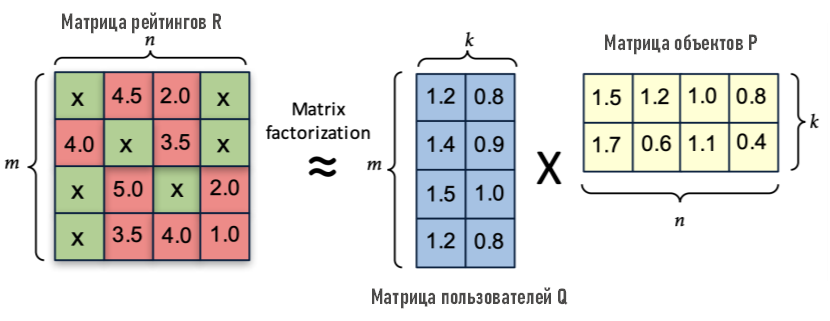

In [75]:
Image('SVD.png', width='75%')

У нас есть матрица рейтингов R. Выполним её сингулярное разложение.
Первые две матрицы перемножим, получим также матрицу $m$ x $n$, в итоге получится такое разложение.

Латентными факторами здесь являются характеристики предметов. SVD уменьшает размерность матрицы рейтингов R, извлекая из нее латентные факторы. Она отображает каждого пользователя и каждый предмет в r-мерное латентное пространство. Такое отображение позволяет четко представить взаимосвязи между пользователями и предметами.

Оценки для матрицы рейтингов получаем по следующей формуле
$$\hat r_{ui} = \langle p_u, q_i \rangle$$

В рекомендательных системах обычно используется матрица пользователь–объект, где строки соответствуют пользователям, столбцы — объектам (например, фильмам или товарам), а значения в ячейках — оценки пользователей. Такая матрица, как правило, является разреженной, поскольку каждый пользователь оценивает лишь небольшое количество объектов.

Сингулярное разложение позволяет представить эту матрицу в виде произведения трёх матриц:

A = U · Σ · Vᵀ

где

U — матрица, описывающая пользователей,

Σ — диагональная матрица сингулярных значений (весов факторов),

Vᵀ — матрица, описывающая объекты.

Такое разложение позволяет представить исходные данные в виде набора скрытых факторов. Эти факторы могут отражать неявные характеристики объектов и предпочтений пользователей. Например, в системе рекомендаций фильмов такими факторами могут быть жанр, стиль фильма, уровень динамики или популярность.

В результате каждый пользователь и каждый объект описываются вектором скрытых признаков в новом пространстве меньшей размерности. Сходство между пользователями и объектами можно вычислять уже в этом пространстве, что значительно упрощает построение рекомендаций.

In [78]:
# Создаем матрицу рейтингов
ratings_matrix = np.ndarray(
    shape=(np.max(ratings_data.movie_id.values), np.max(ratings_data.user_id.values)),
    dtype=np.uint8)
ratings_matrix

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

In [67]:
# Заполнение матрицы оценками
ratings_matrix[ratings_data.movie_id.values-1, ratings_data.user_id.values-1] = ratings_data.rating.values
ratings_matrix

array([[5, 0, 0, ..., 0, 0, 3],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

In [68]:
ratings_data[ratings_data.user_id == 1]

,user_id,movie_id,rating,time
31,1,3186,4,978300019
27,1,1721,4,978300055
22,1,1270,5,978300055
37,1,1022,5,978300055
24,1,2340,3,978300103
36,1,1836,5,978300172
3,1,3408,4,978300275
47,1,1207,4,978300719
7,1,2804,5,978300719
44,1,260,4,978300760


Если использовать эти значения напрямую, алгоритм будет считать:

Film A похож на фильмы с высокими рейтингами

Film B похож на фильмы с низкими рейтингами

Но это не отражает реального сходства вкусов.

Film A просто популярный фильм, а не обязательно похожий на другие.

In [69]:
# Вычисление среднего рейтинга

np.asarray([(np.mean(ratings_matrix, 1))]).T

array([[1.42599338],
       [0.37152318],
       [0.23874172],
       ...,
       [0.03278146],
       [0.02582781],
       [0.24288079]])

In [70]:
# Нормализуем матрицу
normalised_mat = ratings_matrix - np.asarray([(np.mean(ratings_matrix, 1))]).T

A = normalised_mat.T / np.sqrt(ratings_matrix.shape[0] - 1)
A

array([[ 0.05685934, -0.00591061, -0.00379817, ..., -0.00052152,
        -0.0004109 , -0.00386402],
       [-0.02268632, -0.00591061, -0.00379817, ..., -0.00052152,
        -0.0004109 , -0.00386402],
       [-0.02268632, -0.00591061, -0.00379817, ..., -0.00052152,
        -0.0004109 , -0.00386402],
       ...,
       [-0.02268632, -0.00591061, -0.00379817, ..., -0.00052152,
        -0.0004109 , -0.00386402],
       [-0.02268632, -0.00591061, -0.00379817, ..., -0.00052152,
        -0.0004109 , -0.00386402],
       [ 0.02504108, -0.00591061, -0.00379817, ..., -0.00052152,
        -0.0004109 , -0.00386402]])

SVD пытается найти скрытые факторы в данных.

Но если не убрать среднее значение:

- модель будет изучать популярность фильмов,
- а не вкусы пользователей.

После нормализации SVD начинает находить:

- предпочтения пользователей
- скрытые факторы (жанр, стиль, атмосфера фильма и т.д.)

Без нормализации модель видит:

- "Этот фильм просто получает высокие оценки"

После нормализации модель видит:

- "Этот пользователь оценивает этот фильм выше среднего"

Именно это важно для рекомендаций.

In [74]:
U, S, V = np.linalg.svd(A)

In [71]:
# Вычисляем косинусное сходство и возращаем top лучших результатов
def top_cosine_similarity(data, movie_id, top_n=10):
    index = movie_id - 1
    # Каждая строка содержит вектор признаков фильма
    movie_row = data[index, :]
    # Здесь вычисляется длина (норма) каждого вектора фильма.
    norm = np.sqrt(np.einsum('ij, ij -> i', data, data))
    # Вычисление косинусного сходства
    similarity = np.dot(movie_row, data.T) / (norm[index] * norm)
    # Результаты сортируются по убыванию сходства.
    sort_indexes = np.argsort(-similarity)
    return sort_indexes[:top_n]

In [72]:
def print_similar_movies(movie_data, movie_id, V, k, top_n=10):
    # Здесь выбираются k наиболее важных скрытых факторов.
    sliced = V.T[:, :k]
    indexes = top_cosine_similarity(sliced, movie_id, top_n)
    
    print('Рекомендации на основе фильма {0}: \n'.format(
    movie_data[movie_data.movie_id == movie_id].title.values[0]))
    for id in indexes + 1:
        print(movie_data[movie_data.movie_id == id].title.values[0])

In [75]:
k = 50
movie_id = 1
top_n = 10
print_similar_movies(movie_data, movie_id, V, k)

Рекомендации на основе фильма Toy Story (1995): 

Toy Story (1995)
Toy Story 2 (1999)
Babe (1995)
Bug's Life, A (1998)
Pleasantville (1998)
Babe: Pig in the City (1998)
Aladdin (1992)
Stuart Little (1999)
Secret Garden, The (1993)
Tarzan (1999)


In [76]:
k = 50
movie_id = 2
top_n = 10
print_similar_movies(movie_data, movie_id, V, k)

Рекомендации на основе фильма Jumanji (1995): 

Jumanji (1995)
Hook (1991)
Indian in the Cupboard, The (1995)
NeverEnding Story II: The Next Chapter, The (1990)
Dragonheart (1996)
FairyTale: A True Story (1997)
NeverEnding Story, The (1984)
Santa Clause, The (1994)
Simple Wish, A (1997)
Borrowers, The (1997)


## Контентная фильтрация

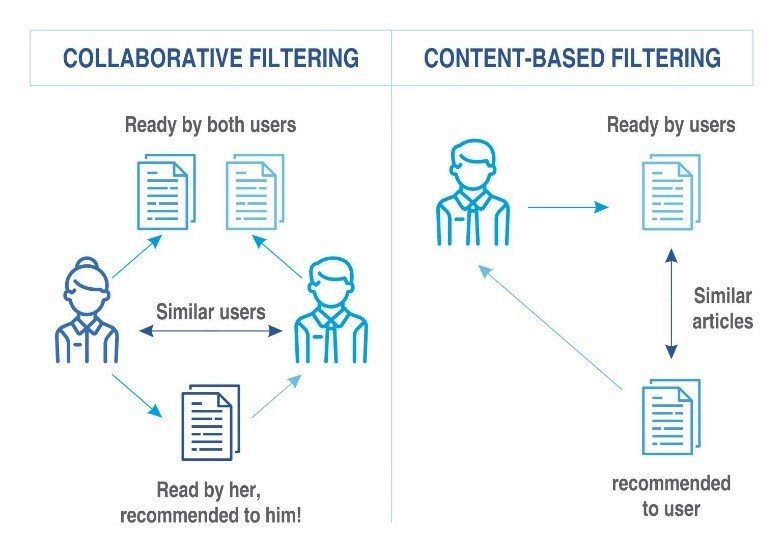

In [77]:
Image('content-filtering.jpg', width='75%')

In [79]:
# Извлекаем год фильма из описания

movie_data['year'] = movie_data.title.str.extract('(\(\d\d\d\d\))',expand=False)
movie_data['year'] = movie_data.year.str.extract('(\d\d\d\d)',expand=False)
movie_data['title'] = movie_data.title.str.replace('(\(\d\d\d\d\))', '')
movie_data['title'] = movie_data['title'].apply(lambda x: x.strip())
movie_data.head()

,movie_id,title,genre,year
0,1,Toy Story (1995),Animation|Children's|Comedy,1995
1,2,Jumanji (1995),Adventure|Children's|Fantasy,1995
2,3,Grumpier Old Men (1995),Comedy|Romance,1995
3,4,Waiting to Exhale (1995),Comedy|Drama,1995
4,5,Father of the Bride Part II (1995),Comedy,1995


In [80]:
# Распарсим жанры

movie_data['genre'] = movie_data.genre.str.split('|')
movie_data.head()

,movie_id,title,genre,year
0,1,Toy Story (1995),"[Animation, Children's, Comedy]",1995
1,2,Jumanji (1995),"[Adventure, Children's, Fantasy]",1995
2,3,Grumpier Old Men (1995),"[Comedy, Romance]",1995
3,4,Waiting to Exhale (1995),"[Comedy, Drama]",1995
4,5,Father of the Bride Part II (1995),[Comedy],1995


In [81]:
# Воспользуемся методом ohe-hot encoding

movie_dataframe = movie_data.copy()

for index, row in movie_data.iterrows():
    for genre in row['genre']:
        movie_dataframe.at[index, genre] = 1
movie_dataframe = movie_dataframe.fillna(0)
movie_dataframe.head()

,movie_id,title,genre,year,Animation,Children's,Comedy,Adventure,Fantasy,Romance,...,Crime,Thriller,Horror,Sci-Fi,Documentary,War,Musical,Mystery,Film-Noir,Western
0,1,Toy Story (1995),"[Animation, Children's, Comedy]",1995,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,Jumanji (1995),"[Adventure, Children's, Fantasy]",1995,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,Grumpier Old Men (1995),"[Comedy, Romance]",1995,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,Waiting to Exhale (1995),"[Comedy, Drama]",1995,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,Father of the Bride Part II (1995),[Comedy],1995,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [82]:
## Тестовый пользователь

current_user = [
            {'title':'Breakfast Club, The (1985)', 'rating':5},
            {'title':'Toy Story (1995)', 'rating':3.5},
            {'title':'Jumanji (1995)', 'rating':2},
            {'title':"Pulp Fiction (1994)", 'rating':5},
            {'title':'Akira (1988)', 'rating':4.5}
         ] 
current_user = pd.DataFrame(current_user)
current_user

,title,rating
0,"Breakfast Club, The (1985)",5.0
1,Toy Story (1995),3.5
2,Jumanji (1995),2.0
3,Pulp Fiction (1994),5.0
4,Akira (1988),4.5


In [83]:
# Добавляем нужные столбцы

id_movies = movie_data[movie_data['title'].isin(current_user['title'].tolist())]
current_user = pd.merge(id_movies, current_user)
current_user

,movie_id,title,genre,year,rating
0,1,Toy Story (1995),"[Animation, Children's, Comedy]",1995,3.5
1,2,Jumanji (1995),"[Adventure, Children's, Fantasy]",1995,2.0
2,296,Pulp Fiction (1994),"[Crime, Drama]",1994,5.0
3,1274,Akira (1988),"[Adventure, Animation, Sci-Fi, Thriller]",1988,4.5
4,1968,"Breakfast Club, The (1985)","[Comedy, Drama]",1985,5.0


In [84]:
# Получаем данные из dataframe
# Выбираем фильмы, которые оценил пользователь
usem_movies = movie_dataframe[movie_dataframe['movie_id'].isin(current_user['movie_id'].tolist())]
usem_movies

,movie_id,title,genre,year,Animation,Children's,Comedy,Adventure,Fantasy,Romance,...,Crime,Thriller,Horror,Sci-Fi,Documentary,War,Musical,Mystery,Film-Noir,Western
0,1,Toy Story (1995),"[Animation, Children's, Comedy]",1995,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,Jumanji (1995),"[Adventure, Children's, Fantasy]",1995,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
293,296,Pulp Fiction (1994),"[Crime, Drama]",1994,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1254,1274,Akira (1988),"[Adventure, Animation, Sci-Fi, Thriller]",1988,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1899,1968,"Breakfast Club, The (1985)","[Comedy, Drama]",1985,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [85]:
# оставляем данные только по жанрам
usem_movies = usem_movies.reset_index(drop=True)
user_genre_table = usem_movies.drop('movie_id', axis=1).drop('title', axis=1).drop('genre', axis=1).drop('year', axis=1)
user_genre_table

,Animation,Children's,Comedy,Adventure,Fantasy,Romance,Drama,Action,Crime,Thriller,Horror,Sci-Fi,Documentary,War,Musical,Mystery,Film-Noir,Western
0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Это профиль пользователя

Теперь создадим профиль объектов

In [87]:
# Создаем таблицу признаков всех фильмов
genre_table = movie_dataframe.set_index(movie_dataframe['movie_id'])
genre_table

,movie_id,title,genre,year,Animation,Children's,Comedy,Adventure,Fantasy,Romance,...,Crime,Thriller,Horror,Sci-Fi,Documentary,War,Musical,Mystery,Film-Noir,Western
movie_id,,,,,,,,,,,,,,,,,,,,,
1,1,Toy Story (1995),"[Animation, Children's, Comedy]",1995,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,Jumanji (1995),"[Adventure, Children's, Fantasy]",1995,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,Grumpier Old Men (1995),"[Comedy, Romance]",1995,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,Waiting to Exhale (1995),"[Comedy, Drama]",1995,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,5,Father of the Bride Part II (1995),[Comedy],1995,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3948,3948,Meet the Parents (2000),[Comedy],2000,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3949,3949,Requiem for a Dream (2000),[Drama],2000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3950,3950,Tigerland (2000),[Drama],2000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [88]:
genre_table.columns

Index(['movie_id', 'title', 'genre', 'year', 'Animation', 'Children's',
       'Comedy', 'Adventure', 'Fantasy', 'Romance', 'Drama', 'Action', 'Crime',
       'Thriller', 'Horror', 'Sci-Fi', 'Documentary', 'War', 'Musical',
       'Mystery', 'Film-Noir', 'Western'],
      dtype='object')

In [89]:
cols = ['movie_id', 'title', 'genre', 'year']

In [90]:
# Далее удаляются лишние столбцы
# Остаётся матрица жанров фильмов

genre_table = genre_table.drop(cols, axis=1)
genre_table.head()

,Animation,Children's,Comedy,Adventure,Fantasy,Romance,Drama,Action,Crime,Thriller,Horror,Sci-Fi,Documentary,War,Musical,Mystery,Film-Noir,Western
movie_id,,,,,,,,,,,,,,,,,,
1,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [91]:
# Считаем средневзвешенную оценку для каждого фильма на основе профиля пользователя
# Формируем профиль пользователя
# Здесь строится профиль интересов пользователя.
# Фактически вычисляется взвешенная сумма жанров с учётом рейтингов пользователя.
user_profile = user_genre_table.transpose().dot(current_user['rating'])
user_profile

Animation       8.0
Children's      5.5
Comedy          8.5
Adventure       6.5
Fantasy         2.0
Romance         0.0
Drama          10.0
Action          0.0
Crime           5.0
Thriller        4.5
Horror          0.0
Sci-Fi          4.5
Documentary     0.0
War             0.0
Musical         0.0
Mystery         0.0
Film-Noir       0.0
Western         0.0
dtype: float64

In [92]:
# Вычисляем оценку для всех фильмов
#Здесь выполняется:

#1️⃣ умножение жанров фильма на профиль пользователя
#2️⃣ суммирование значений
#3️⃣ нормализация результата

#Это фактически вычисляет:
#насколько жанры фильма совпадают с предпочтениями пользователя

recommendation_table = ((genre_table*user_profile).sum(axis=1))/(user_profile.sum())
# Фильмы сортируются по степени соответствия интересам пользователя.
recommendation_table = recommendation_table.sort_values(ascending=False)
recommendation_table.head()

movie_id
673     0.559633
1566    0.522936
2054    0.495413
2138    0.467890
1259    0.458716
dtype: float64

In [93]:
movie_data.loc[movie_data['movie_id'].isin(recommendation_table.head(20).keys())]

,movie_id,title,genre,year
33,34,Babe (1995),"[Children's, Comedy, Drama]",1995
399,403,Two Crimes (1995),"[Comedy, Crime, Drama]",1995
667,673,Space Jam (1996),"[Adventure, Animation, Children's, Comedy, Fan...",1996
1001,1014,Pollyanna (1960),"[Children's, Comedy, Drama]",1960
1239,1259,Stand by Me (1986),"[Adventure, Comedy, Drama]",1986
1526,1566,Hercules (1997),"[Adventure, Animation, Children's, Comedy, Mus...",1997
1663,1711,Midnight in the Garden of Good and Evil (1997),"[Comedy, Crime, Drama, Mystery]",1997
1745,1809,Hana-bi (1997),"[Comedy, Crime, Drama]",1997
1748,1812,Wide Awake (1998),"[Children's, Comedy, Drama]",1998
1849,1918,Lethal Weapon 4 (1998),"[Action, Comedy, Crime, Drama]",1998


## Гибридные рекомендательные системы

Варианты `Гибридных Рекомендательных Систем` (ГРС):

1. «Взвешенная» ГРС. Используется несколько независимых подходов для формирования рекомендаций. В качестве результата берется взвешенная сумма результатов, полученных с помощью данных подходов.
2. ГРС «с ветвлениями». В этом случае ГРС состоит как минимум из двух фаз. Первая фаза связана с предварительным анализом данных. Во второй фазе выбирается наиболее подходящий алгоритм формирования рекомендаций на основе предварительного анализа. Одной из разновидностей данного подхода является введение в модель обратной связи, рекомендации запоминаются в системе и используются в первой фазе, что влияет на выбор алгоритма во второй фазе.
3. «Каскадная» ГРС или «конвейер». В этом случае несколько рекомендательных алгоритмов располагают последовательно, каждый следующий алгоритм уточняет результаты предыдущего.
4. «Многоуровневая» ГРС. В этом случае выход одного рекомендательного алгоритма рассматривается как вход для другого алгоритма.